# **TP — Modèles génératifs avec PyTorch sur MNIST**
**Partie I : Discriminatif · Autoencodeur · Variational Autoencoder (VAE)**

Objectifs :
1. Charger MNIST.
2. Créer, entraîner et évaluer un **modèle discriminatif** (classifieur).
3. Créer, entraîner, évaluer et explorer un **autoencodeur** simple.
4. Créer, entraîner, évaluer et explorer un **VAE**.

## 0. Préparation de l'environnement (UV + VS Code)

Dans un dossier ouvert dans VS Code, exécuter dans le terminal :

```bash
uv init --python=3.11
uv venv
# Activer l'environnement
#   Windows : .venv\Scripts\activate
#   Linux/macOS : source .venv/bin/activate
uv add ipykernel torch torchvision torcheval matplotlib numpy
```

Puis créer ce notebook `.ipynb` dans le dossier, et sélectionner le kernel `.venv` (en haut à droite dans VS Code).
Les cellules suivantes vérifient que tout est bien installé.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Reproductibilité
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print("PyTorch :", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Device  :", device)

PyTorch : 2.15.0+cpu
Device  : cpu


## 1. Chargement du dataset MNIST

MNIST : 70 000 images en niveaux de gris de chiffres manuscrits, de taille $28\times 28 = 784$ pixels, label entre 0 et 9
(60 000 images d'entraînement, 10 000 de test).

`transforms.ToTensor()` convertit chaque image en tenseur `(1, 28, 28)` avec des pixels dans $[0,1]$ — indispensable pour utiliser
une sortie `Sigmoid` et la `BCE` plus loin.

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print("Train :", len(train_dataset), "images")
print("Test  :", len(test_dataset), "images")

x0, y0 = train_dataset[0]
print("Shape d'une image :", tuple(x0.shape), "| min/max :", x0.min().item(), x0.max().item())

100.0%
100.0%
100.0%
100.0%

Train : 60000 images
Test  : 10000 images
Shape d'une image : (1, 28, 28) | min/max : 0.0 1.0


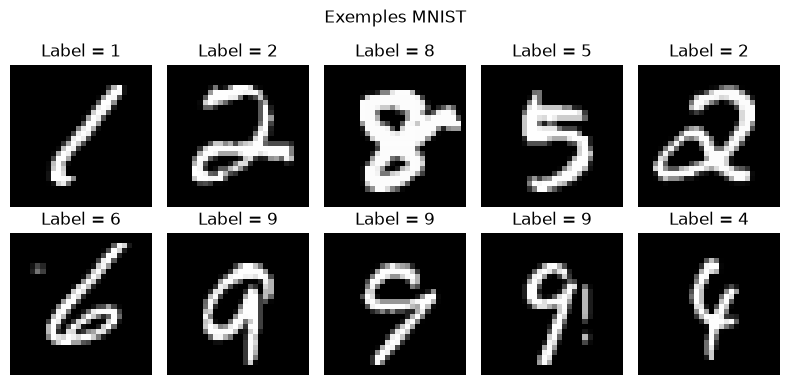

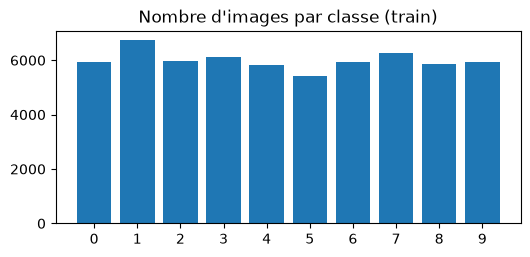

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.suptitle("Exemples MNIST")
plt.tight_layout()
plt.show()

# Répartition des classes
counts = torch.bincount(train_dataset.targets)
plt.figure(figsize=(6, 2.5))
plt.bar(range(10), counts.numpy())
plt.xticks(range(10)); plt.title("Nombre d'images par classe (train)")
plt.show()

# **2. Modèle discriminatif : apprendre $P(y\mid x)$**

Un modèle discriminatif apprend à **séparer les classes** : étant donnée une image $x$, il prédit le chiffre $y$.
Il ne sait pas *générer* d'image.

Architecture : `Flatten (784) → Linear(128) → ReLU → Linear(10)`.
Les 10 sorties sont des **logits** (pas de softmax : `CrossEntropyLoss` l'intègre).

$$\mathcal{L}_{CE} = -\frac{1}{N}\sum_{i=1}^{N}\log P_\theta(y_i\mid x_i)$$

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
print(classifier)
print("Paramètres :", sum(p.numel() for p in classifier.parameters()))

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Paramètres : 101770


In [5]:
criterion = nn.CrossEntropyLoss()
clf_optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.size(0)
    return correct / total

def train_classifier(model, loader, epochs=5):
    history = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)

            clf_optimizer.zero_grad()
            loss.backward()
            clf_optimizer.step()
            total_loss += loss.item()

        avg = total_loss / len(loader)
        acc = evaluate_classifier(model, test_loader)
        history.append((avg, acc))
        print(f"Epoch {epoch+1}/{epochs} - Loss = {avg:.4f} - Test acc = {100*acc:.2f}%")
    return history

clf_history = train_classifier(classifier, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.4115 - Test acc = 93.28%
Epoch 2/5 - Loss = 0.1928 - Test acc = 95.45%
Epoch 3/5 - Loss = 0.1373 - Test acc = 96.20%
Epoch 4/5 - Loss = 0.1062 - Test acc = 97.02%
Epoch 5/5 - Loss = 0.0847 - Test acc = 97.36%


### Évaluation

In [6]:
accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy finale sur le test = {100*accuracy:.2f}%")

# Autre façon : avec torcheval
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_with_torcheval(model, loader):
    model.eval()
    metric = MulticlassAccuracy()
    for x, y in loader:
        metric.update(model(x.to(device)).cpu(), y)
    return metric.compute().item()

print(f"Accuracy (torcheval)      = {100*evaluate_with_torcheval(classifier, test_loader):.2f}%")

Accuracy finale sur le test = 97.36%


c:\Users\aliaa\Desktop\Modeles_Generatifs\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy (torcheval)      = 97.36%


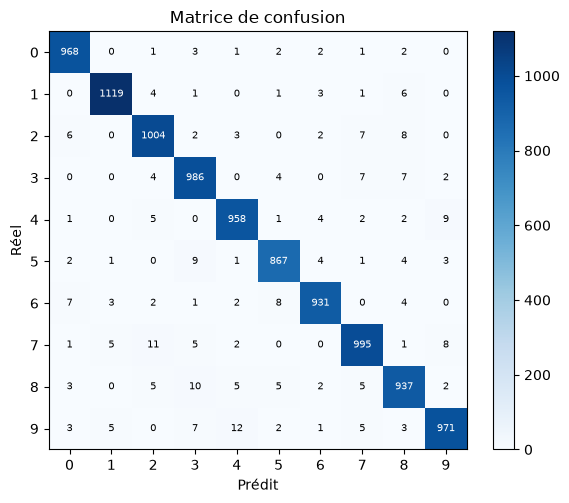

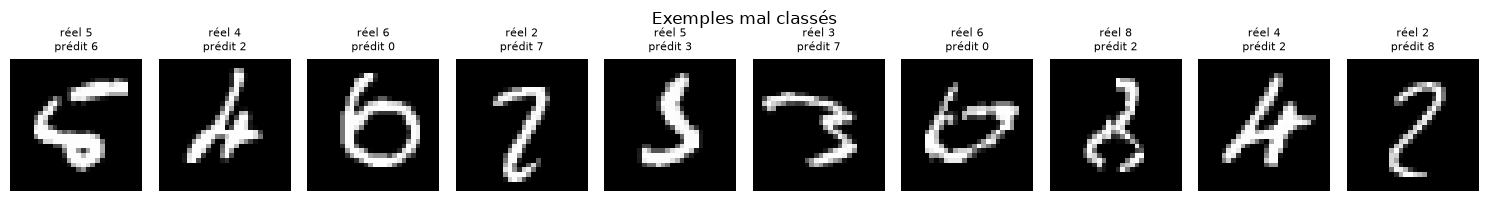

In [7]:
# Matrice de confusion + exemples mal classés
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, ys, xs = [], [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(1).cpu()); ys.append(y); xs.append(x)
    return torch.cat(preds), torch.cat(ys), torch.cat(xs)

preds, ys, xs = predict_all(classifier, test_loader)

cm = torch.zeros(10, 10, dtype=torch.int64)
for t, p in zip(ys, preds):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm.numpy(), cmap="Blues")
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

wrong = (preds != ys).nonzero().squeeze()[:10]
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, idx in zip(axes, wrong):
    ax.imshow(xs[idx].squeeze(), cmap="gray"); ax.axis("off")
    ax.set_title(f"réel {ys[idx].item()}\nprédit {preds[idx].item()}", fontsize=8)
plt.suptitle("Exemples mal classés"); plt.tight_layout(); plt.show()

**Bilan :** le réseau apprend $x \Rightarrow y$. Il *discrimine* les classes mais ne sait pas produire un nouveau « 7 ».
Pour générer, il faut modéliser la structure des images elles-mêmes → autoencodeur, puis VAE.

# **3. Autoencodeur simple**

Un autoencodeur apprend à **reconstruire son entrée** à travers un goulot d'étranglement :

$$x \xrightarrow{\text{encodeur}} z \xrightarrow{\text{décodeur}} \hat{x}$$

Ici, l'espace latent est volontairement de dimension **2** pour pouvoir le visualiser directement.
Loss de reconstruction (MSE) :

$$\mathcal{L}_{rec}=\frac{1}{N}\sum_{i}\lVert x_i-\hat{x}_i\rVert^2$$

Pas besoin des labels : c'est de l'apprentissage **non supervisé**.

In [8]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 32),  nn.ReLU(),
            nn.Linear(32, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),  nn.ReLU(),
            nn.Linear(32, 128),         nn.ReLU(),
            nn.Linear(128, 784),        nn.Sigmoid(),   # pixels dans [0, 1]
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        return self.decode(self.encode(x))

ae = Autoencoder(latent_dim=2).to(device)
print(ae)

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [9]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

@torch.no_grad()
def evaluate_ae(model, loader):
    model.eval()
    total = 0.0
    for x, _ in loader:
        x = x.to(device)
        total += ae_criterion(model(x), x).item() * x.size(0)
    return total / len(loader.dataset)

def train_autoencoder(model, loader, epochs=10):
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for x, _ in loader:
            x = x.to(device)
            loss = ae_criterion(model(x), x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()
            total += loss.item()

        tr, te = total / len(loader), evaluate_ae(model, test_loader)
        history.append((tr, te))
        print(f"Epoch {epoch+1}/{epochs} - Train MSE = {tr:.4f} - Test MSE = {te:.4f}")
    return history

ae_history = train_autoencoder(ae, train_loader, epochs=10)

Epoch 1/10 - Train MSE = 0.0650 - Test MSE = 0.0533
Epoch 2/10 - Train MSE = 0.0512 - Test MSE = 0.0489
Epoch 3/10 - Train MSE = 0.0477 - Test MSE = 0.0463
Epoch 4/10 - Train MSE = 0.0459 - Test MSE = 0.0453
Epoch 5/10 - Train MSE = 0.0448 - Test MSE = 0.0442
Epoch 6/10 - Train MSE = 0.0438 - Test MSE = 0.0433
Epoch 7/10 - Train MSE = 0.0431 - Test MSE = 0.0426
Epoch 8/10 - Train MSE = 0.0424 - Test MSE = 0.0420
Epoch 9/10 - Train MSE = 0.0419 - Test MSE = 0.0417
Epoch 10/10 - Train MSE = 0.0414 - Test MSE = 0.0413


In [ ]:
plt.figure(figsize=(5, 3))
plt.plot([h[0] for h in ae_history], label="train")
plt.plot([h[1] for h in ae_history], label="test")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Autoencodeur — courbe de perte"); plt.legend()
plt.show()

### Évaluation visuelle : reconstructions

In [ ]:
def show_reconstructions(model, loader, title, vae=False, n=10):
    model.eval()
    x, _ = next(iter(loader))
    x = x[:n].to(device)
    with torch.no_grad():
        x_hat = model(x)[0] if vae else model(x)

    fig, axes = plt.subplots(2, n, figsize=(1.5 * n, 3.2))
    for i in range(n):
        axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray"); axes[0, i].axis("off")
        axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray"); axes[1, i].axis("off")
    axes[0, 0].set_title("Original", fontsize=9, loc="left")
    axes[1, 0].set_title("Reconstruit", fontsize=9, loc="left")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_reconstructions(ae, test_loader, "Autoencodeur (latent 2D)")

### Exploration : l'espace latent 2D

Chaque image de test est encodée en un point $(z_1, z_2)$, coloré selon son vrai chiffre.

In [ ]:
@torch.no_grad()
def encode_dataset(encode_fn, loader):
    zs, ys = [], []
    for x, y in loader:
        zs.append(encode_fn(x.to(device)).cpu()); ys.append(y)
    return torch.cat(zs).numpy(), torch.cat(ys).numpy()

ae.eval()
Z, Y = encode_dataset(ae.encode, test_loader)

plt.figure(figsize=(8, 6))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4, cmap="tab10")
plt.colorbar(sc, ticks=range(10))
plt.xlabel("z1"); plt.ylabel("z2"); plt.title("Espace latent de l'autoencodeur")
plt.show()

**Observations attendues :** les chiffres forment des groupes (1 très compact, 4/9 et 3/5/8 qui se chevauchent),
mais l'espace est **irrégulier** : grandes zones vides, échelle arbitraire, pas de structure imposée.

### Génération à partir d'un point latent

In [ ]:
# 1) Décoder le point latent moyen d'une classe
@torch.no_grad()
def generer_chiffre(model, dataset, chiffre):
    model.eval()
    imgs = dataset.data[dataset.targets == chiffre].float().div(255).unsqueeze(1)
    z_moyen = model.encode(imgs.to(device)).mean(dim=0, keepdim=True)
    return model.decode(z_moyen).cpu(), z_moyen.cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for d, ax in enumerate(axes):
    img, _ = generer_chiffre(ae, train_dataset, d)
    ax.imshow(img[0, 0], cmap="gray"); ax.set_title(str(d)); ax.axis("off")
plt.suptitle("Décodage du centre de chaque classe (AE)"); plt.tight_layout(); plt.show()

In [ ]:
# 2) Balayage d'une grille 2D dans la zone occupée par les données
lo, hi = np.percentile(Z, 2, axis=0), np.percentile(Z, 98, axis=0)
n = 15
gx, gy = np.linspace(lo[0], hi[0], n), np.linspace(hi[1], lo[1], n)

canvas = np.zeros((28 * n, 28 * n))
with torch.no_grad():
    for i, yi in enumerate(gy):
        for j, xi in enumerate(gx):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            canvas[i*28:(i+1)*28, j*28:(j+1)*28] = ae.decode(z)[0, 0].cpu().numpy()

plt.figure(figsize=(8, 8)); plt.imshow(canvas, cmap="gray"); plt.axis("off")
plt.title("Grille de l'espace latent de l'AE"); plt.show()

In [ ]:
# 3) Interpolation entre deux vraies images dans l'espace latent
@torch.no_grad()
def interpolate(model, x_a, x_b, steps=10, encode_fn=None):
    model.eval()
    enc = encode_fn or model.encode
    za, zb = enc(x_a.to(device)), enc(x_b.to(device))
    ts = torch.linspace(0, 1, steps, device=device).view(-1, 1)
    z = (1 - ts) * za + ts * zb
    return model.decode(z).cpu()

idx_a = (test_dataset.targets == 3).nonzero()[0].item()
idx_b = (test_dataset.targets == 8).nonzero()[0].item()
xa, xb = test_dataset[idx_a][0].unsqueeze(0), test_dataset[idx_b][0].unsqueeze(0)

seq = interpolate(ae, xa, xb)
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, im in zip(axes, seq):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
plt.suptitle("Interpolation 3 → 8 (AE)"); plt.tight_layout(); plt.show()

### Effet de la taille de l'espace latent

Plus la dimension latente est grande, meilleure est la reconstruction (mais plus on perd la possibilité de visualiser).

In [ ]:
results = {}
for d in [2, 8, 32]:
    m = Autoencoder(latent_dim=d).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for _ in range(5):
        m.train()
        for x, _ in train_loader:
            x = x.to(device)
            loss = ae_criterion(m(x), x)
            opt.zero_grad(); loss.backward(); opt.step()
    results[d] = (m, evaluate_ae(m, test_loader))
    print(f"latent_dim = {d:>2} -> Test MSE = {results[d][1]:.4f}")

x, _ = next(iter(test_loader)); x = x[:8].to(device)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for j in range(8):
    axes[0, j].imshow(x[j].cpu().squeeze(), cmap="gray")
for r, d in enumerate(results, start=1):
    with torch.no_grad(): out = results[d][0](x).cpu()
    for j in range(8):
        axes[r, j].imshow(out[j].squeeze(), cmap="gray")
    axes[r, 0].set_ylabel(f"d={d}")
for a in axes.flat: a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_ylabel("original")
plt.suptitle("Reconstructions selon la dimension latente"); plt.tight_layout(); plt.show()

### Limite de l'autoencodeur classique

L'AE apprend à **compresser/reconstruire**, mais son espace latent n'est pas organisé : tirer un $z$ au hasard
(par exemple $\mathcal N(0,I)$) donne souvent une image sans signification, car rien n'oblige les codes à occuper
l'espace de manière continue. Testons-le :

In [ ]:
with torch.no_grad():
    z = torch.randn(20, 2, device=device) * torch.tensor(Z.std(0), device=device) + torch.tensor(Z.mean(0), device=device)
    samples = ae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for ax, im in zip(axes.flat, samples):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
plt.suptitle("AE : décodage de points latents aléatoires (souvent flous / incohérents)")
plt.tight_layout(); plt.show()

# **4. Variational Autoencoder (VAE)**

Au lieu d'associer une image à **un point** $z$, l'encodeur produit une **distribution** :

$$q_\phi(z\mid x)=\mathcal N\big(\mu_\phi(x),\ \sigma_\phi^2(x)\big)$$

et on force cette distribution à rester proche d'un a priori $p(z)=\mathcal N(0,I)$. On peut alors **générer** : tirer
$z\sim\mathcal N(0,I)$ puis décoder.

### Reparameterization trick
Échantillonner $z$ directement empêche la rétropropagation. On écrit donc :

$$z=\mu+\sigma\odot\varepsilon,\qquad \varepsilon\sim\mathcal N(0,I)$$

Le hasard est isolé dans $\varepsilon$, et le gradient peut passer par $\mu$ et $\sigma$.
Le réseau prédit $\log\sigma^2$ (`logvar`) pour la stabilité numérique : $\sigma=\exp(\tfrac12\,\text{logvar})$.

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 64),  nn.ReLU(),
        )
        self.fc_mu     = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),  nn.ReLU(),
            nn.Linear(64, 256),         nn.ReLU(),
            nn.Linear(256, 784),        nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = VAE(latent_dim=2).to(device)
print(vae)

### Fonction de perte (ELBO négatif)

$$\mathcal L = \underbrace{\sum_{pixels} \text{BCE}(\hat x, x)}_{\text{reconstruction}} \;+\; \beta\,\underbrace{\Big(-\tfrac12\sum_j \big(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\big)\Big)}_{KL\big(q(z|x)\,\|\,\mathcal N(0,I)\big)}$$

- **Reconstruction** : le décodeur doit retrouver l'image.
- **KL** : régularise l'espace latent pour qu'il ressemble à $\mathcal N(0,I)$ (continu, centré, échantillonnable).
- $\beta$ règle le compromis (β = 1 : VAE standard).

In [ ]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl  = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec + beta * kl, rec, kl

@torch.no_grad()
def evaluate_vae(model, loader, beta=1.0):
    model.eval()
    tot = rec = kl = 0.0
    for x, _ in loader:
        x = x.to(device)
        x_hat, mu, logvar = model(x)
        l, r, k = vae_loss(x_hat, x, mu, logvar, beta)
        tot += l.item(); rec += r.item(); kl += k.item()
    n = len(loader.dataset)
    return tot / n, rec / n, kl / n

def train_vae(model, loader, epochs=20, beta=1.0, lr=1e-3, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        tot = rec = kl = 0.0
        for x, _ in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, r, k = vae_loss(x_hat, x, mu, logvar, beta)

            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); rec += r.item(); kl += k.item()

        n = len(loader.dataset)
        te = evaluate_vae(model, test_loader, beta)
        history.append((tot / n, rec / n, kl / n, te[0]))
        if verbose:
            print(f"Epoch {epoch+1:>2}/{epochs} | Loss={tot/n:.2f} | Rec={rec/n:.2f} | "
                  f"KL={kl/n:.2f} | Test loss={te[0]:.2f}")
    return history

vae_history = train_vae(vae, train_loader, epochs=20)

In [ ]:
h = np.array(vae_history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(h[:, 0], label="train"); axes[0].plot(h[:, 3], label="test")
axes[0].set_title("Loss totale (par image)"); axes[0].legend(); axes[0].set_xlabel("Epoch")
axes[1].plot(h[:, 1], label="reconstruction"); axes[1].plot(h[:, 2], label="KL")
axes[1].set_title("Composantes de la loss"); axes[1].legend(); axes[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

### Évaluation : reconstructions

In [ ]:
show_reconstructions(vae, test_loader, "VAE (latent 2D)", vae=True)

### Espace latent du VAE

On trace la moyenne $\mu(x)$ de chaque image de test. Contrairement à l'AE, l'espace est **centré, compact et continu**
(proche d'une gaussienne standard).

In [ ]:
vae.eval()
MU, Y = encode_dataset(lambda x: vae.encode(x)[0], test_loader)

plt.figure(figsize=(8, 6))
sc = plt.scatter(MU[:, 0], MU[:, 1], c=Y, s=4, cmap="tab10")
plt.colorbar(sc, ticks=range(10))
plt.xlabel("μ1"); plt.ylabel("μ2"); plt.title("Espace latent du VAE")
plt.show()

print("Moyenne des μ :", MU.mean(0).round(2), "| écart-type :", MU.std(0).round(2))

### Génération de nouveaux chiffres : $z\sim\mathcal N(0,I)$

In [ ]:
vae.eval()
with torch.no_grad():
    z = torch.randn(20, 2, device=device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for ax, im in zip(axes.flat, samples):
    ax.imshow(im.squeeze(), cmap="gray"); ax.axis("off")
plt.suptitle("Nouveaux chiffres générés par le VAE"); plt.tight_layout(); plt.show()

### Exploration manuelle : grille de l'espace latent

In [ ]:
n = 15
grid_x = np.linspace(-3, 3, n)
grid_y = np.linspace(3, -3, n)   # haut = y positif

canvas = np.zeros((28 * n, 28 * n))
with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            canvas[i*28:(i+1)*28, j*28:(j+1)*28] = vae.decode(z)[0, 0].cpu().numpy()

plt.figure(figsize=(9, 9))
plt.imshow(canvas, cmap="gray", extent=[-3, 3, -3, 3])
plt.xlabel("z1"); plt.ylabel("z2")
plt.title("Parcours continu de l'espace latent du VAE")
plt.show()

In [ ]:
# Interpolation entre deux vraies images (même fonction que pour l'AE, mais sur μ)
seq = interpolate(vae, xa, xb, steps=10, encode_fn=lambda x: vae.encode(x)[0])

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, im in zip(axes, seq):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
plt.suptitle("Interpolation 3 → 8 (VAE) : transition plus progressive qu'avec l'AE")
plt.tight_layout(); plt.show()

### Influence de β et de la dimension latente

- $\beta$ grand → plus de régularisation (espace très lisse) mais reconstructions plus floues.
- $\beta$ petit → meilleures reconstructions mais espace moins structuré (se rapproche d'un AE).
- Dimension latente plus grande → images plus nettes.

(3 epochs par configuration pour rester rapide ; augmentez pour de meilleurs résultats.)

In [ ]:
configs = [(2, 0.1), (2, 1.0), (2, 4.0), (16, 1.0)]
fig, axes = plt.subplots(len(configs), 10, figsize=(13, 1.4 * len(configs)))

for r, (d, beta) in enumerate(configs):
    torch.manual_seed(SEED)
    m = VAE(latent_dim=d).to(device)
    train_vae(m, train_loader, epochs=3, beta=beta, verbose=False)
    _, rec, kl = evaluate_vae(m, test_loader, beta)
    print(f"latent={d:>2}, beta={beta:<4} -> Rec={rec:.2f}  KL={kl:.2f}")
    with torch.no_grad():
        imgs = m.decode(torch.randn(10, d, device=device)).cpu()
    for j in range(10):
        axes[r, j].imshow(imgs[j].squeeze(), cmap="gray"); axes[r, j].set_xticks([]); axes[r, j].set_yticks([])
    axes[r, 0].set_ylabel(f"d={d}\nβ={beta}", rotation=0, labelpad=28, va="center")
plt.suptitle("Échantillons générés selon (dimension latente, β)"); plt.tight_layout(); plt.show()

## Conclusion

| Modèle | Apprend | Espace latent | Génération |
|---|---|---|---|
| Classifieur | $P(y\mid x)$ | — | ✗ |
| Autoencodeur | $x \to z \to \hat x$ | irrégulier, trous | ✗ (peu fiable) |
| **VAE** | $q(z\mid x)$ et $p(x\mid z)$ + prior $\mathcal N(0,I)$ | continu, régulier | ✓ $z\sim\mathcal N(0,I)$ |

Le VAE produit toutefois des images **floues** (loss de reconstruction moyenne en pixels). Les GAN et les modèles de
diffusion (parties suivantes du cours) améliorent la netteté.